<a href="https://colab.research.google.com/github/Kevin-AngelQD/padp/blob/main/PracticaRegresionLinealMultiple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Práctica: Regresión Lineal Múltiple
---


## Datos del Estudiante

*   Apellidos y Nombre: Quiñonez Dominguez Kevin Angel
*   Matrícula: 271758

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, el estudiante será capaz de **aplicar regresión lineal múltiple utilizando Scikit-Learn para modelar la relación entre varias variables independientes y una variable dependiente**, verificar los supuestos del modelo, interpretar los coeficientes, analizar la correlación entre predictores y evaluar el rendimiento del modelo utilizando métricas como el MSE, RMSE y R².

Datos
Trabajarás con el archivo `advertising.csv`, que contiene información sobre el gasto publicitario en diferentes medios y las ventas obtenidas:

-`TV`: inversión en publicidad televisiva.

-`Radio`: inversión en publicidad en radio.

-`Newspaper`: inversión en publicidad en periódicos.

`Sales`: ventas del producto (variable dependiente).

## Parte 1: Carga de datos y bibliotecas
1. Importa las bibliotecas necesarias.
2. Carga el archivo `advertising.csv`.
3. Muestra las primeras filas del dataframe.
4. Describe estadísticamente las variables.

In [1]:
# Tu código aquí

import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from sklearn import datasets
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from statsmodels.tools.tools import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from google.colab import drive
drive.mount('/content/drive')

#Lectura del conjunto de Datos
df = pd.read_csv('drive/MyDrive/Unidad03/advertising.csv')
print("--- Primeras 5 filas del DataFrame ---")
display(df.head())

print("\n--- Descripción estadística de las variables ---")
display(df.describe().round(2))

Mounted at /content/drive
--- Primeras 5 filas del DataFrame ---


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9



--- Descripción estadística de las variables ---


,TV,Radio,Newspaper,Sales
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,15.13
std,85.85,14.85,21.78,5.28
min,0.70,0.00,0.30,1.60
25%,74.38,9.98,12.75,11.00
50%,149.75,22.90,25.75,16.00
75%,218.82,36.52,45.10,19.05
max,296.40,49.60,114.00,27.00


## Parte 2: Análisis exploratorio de los datos
### 2.1  Análisis de la Relación Lineal entre la variable dependiente y las independientes
1. Grafica dispersión entre cada variable independiente (`TV`, `Radio`, `Newspaper`) y `Sales`. Usa también regplot.
2. Interpreta visualmente la relación entre variables.

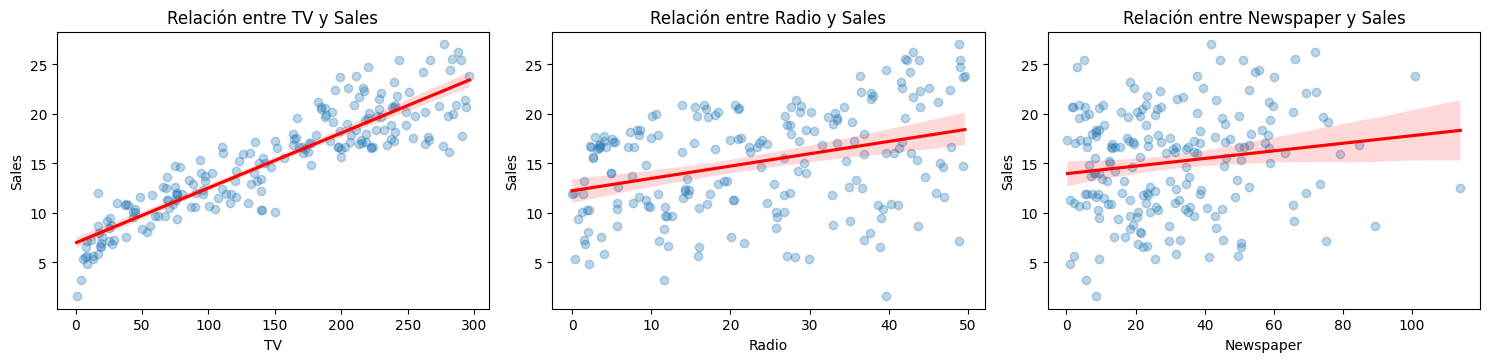

In [2]:
# Gráficos de dispersión

X = df.drop(columns='Sales')  # Características
y = df['Sales']  # Variable dependiente (precio)

plt.figure(figsize=(15, 10))
for i, col in enumerate(X.columns):
    plt.subplot(3, 3, i + 1)
    sns.regplot(x=X[col], y=y, scatter_kws={'alpha':0.3}, line_kws={'color': 'red'})
    plt.title(f"Relación entre {col} y Sales")

plt.tight_layout()
plt.show()





**A. Relación entre TV y Sales (Fuerte y Lineal)**



*   **Apreciación:** Muestra una fuerte tendencia positiva y clara relación lineal.   
*   **Interpretación:** A medida que aumenta el presupuesto en publicidad por televisión, las ventas suben de forma muy consistente. Los puntos están muy cerca de la línea de regresión roja, lo que indica que TV es un excelente predictor individual de Sales.

**B. Relación entre Radio y Sales (Moderada Positiva)**



*   **Apreciación:** Muestra una tendencia positiva moderada pero con mayor dispersión de los puntos a lo largo del eje vertical.   
*   **Interpretación:** Existe una relación favorable entre la inversión en Radio y las ventas, aunque con mayor variabilidad (hay presupuestos altos con ventas bajas y viceversa).
Sigue siendo una variable predictiva útil pero menos precisa que TV por sí sola.   


**C. Relación entre Newspaper y Sales (Débil / Casi Nula)**



*   **Apreciación:** La pendiente de la línea roja es prácticamente plana y la nube de puntos se encuentra extremadamente dispersa (ruido).  
*   **Interpretación:** Existe una relación lineal muy débil o casi nula entre la inversión en Periódicos y las Ventas. La banda sombreada de confianza se ensancha en valores altos, indicando alta incertidumbre. Esta variable aporta poco o nada al modelo de regresión.

### 2.2: Correlación entre variables
1. Calcula la matriz de correlación.
2. Visualízala con un heatmap.
3. Responde: ¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores?

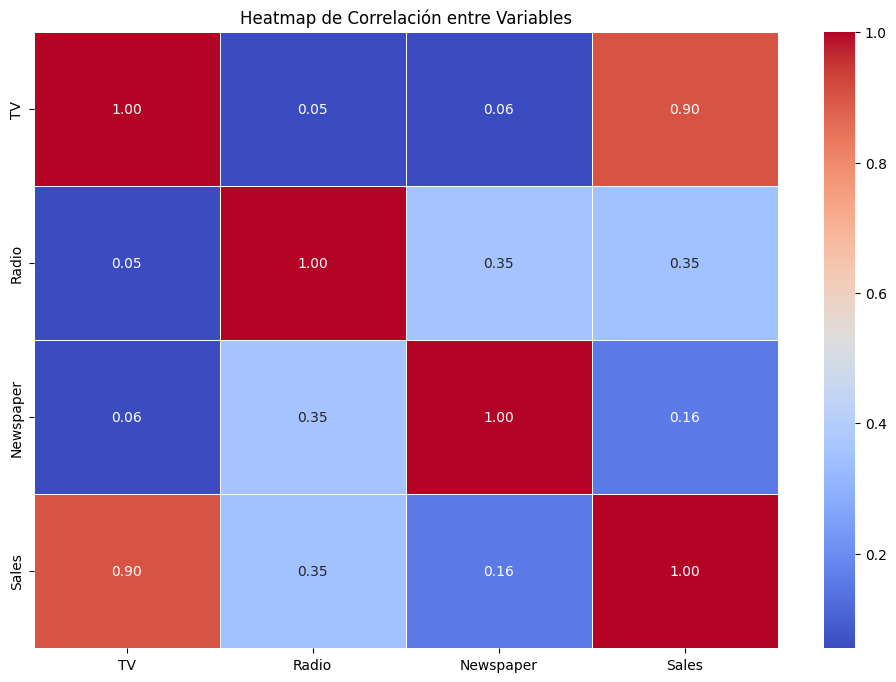

In [3]:
# Correlación y heatmap
plt.figure(figsize=(12, 8))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', cbar=True, linewidths=0.5)
plt.title("Heatmap de Correlación entre Variables")
plt.show()

1. **¿Qué variables están más correlacionadas con Sales?**



*   TV ($0.90$): Tiene una correlación positiva sumamente fuerte con las ventas. Es el predictor principal del modelo.  
*   Radio ($0.35$): Presenta una correlación positiva moderada con Sales. Aporta señal predictiva pero de menor magnitud.   
*   Newspaper ($0.16$): Muestra una correlación débil con Sales.    

2. **¿Hay correlación alta entre predictores (variables independientes)?**

Este es un hallazgo clave para un modelo de regresión: NO existe un problema grave de multicolinealidad entre los predictores principales, lo cual es excelente.


*   TV vs Radio ($0.05$): Correlación prácticamente nula. Significa que la inversión en televisión y la inversión en radio son totalmente independientes entre sí.
*    TV vs Newspaper ($0.06$): Correlación prácticamente nula.
*    Radio vs Newspaper ($0.35$): Muestran una correlación moderada entre ellos.

## Parte 3. Multicolinealidad
1. Calcula el VIF (Variance Inflation Factor) para cada predictor.
2. Crea un diagrama de barras  para mostrar el  VIF
3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?


### Análisis de Multicolinealidad ###
    Variable       VIF
0      const  1.000000
1         TV  1.004611
2      Radio  1.144952
3  Newspaper  1.145187


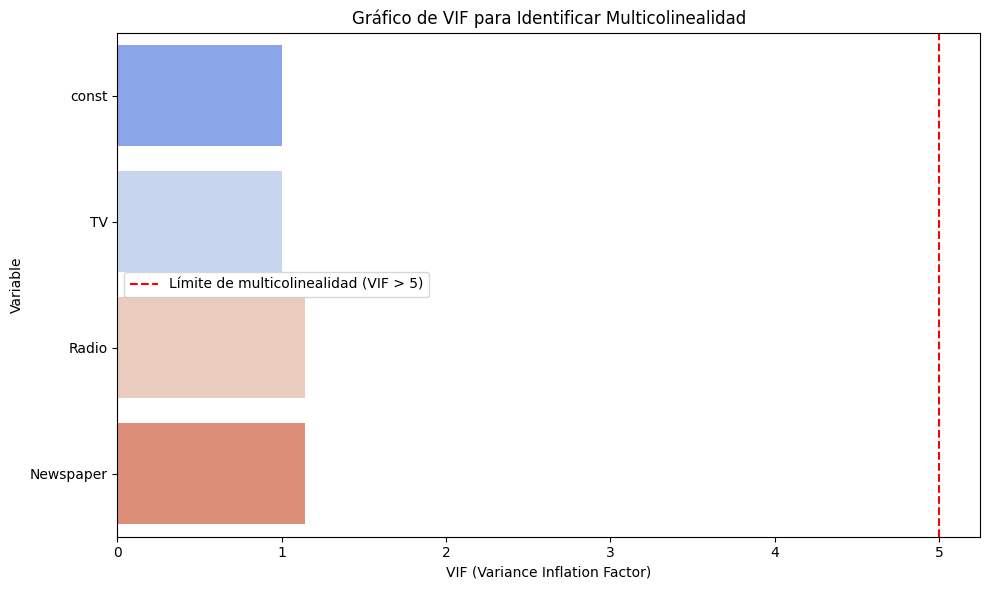

In [4]:
#Multicolinealidad
# El VIF evalúa la colinealidad de cada variable con respecto a las demás. VIF > 5 o 10 indica posible multicolinealidad.

# Agregar constante para calcular el VIF
X = add_constant(df.drop(columns=['Sales']))  # Matriz de características sin la variable dependiente
vif_data = pd.DataFrame()
vif_data['Variable'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

print("\n### Análisis de Multicolinealidad ###")
print(vif_data)

#Visualización de VIF
plt.figure(figsize=(10, 6))
sns.barplot(x='VIF', y='Variable', data=vif_data, hue='Variable', palette='coolwarm', legend=False)
plt.axvline(x=5, color='red', linestyle='--', label='Límite de multicolinealidad (VIF > 5)')
plt.xlabel('VIF (Variance Inflation Factor)')
plt.title('Gráfico de VIF para Identificar Multicolinealidad')
plt.legend()
plt.tight_layout()
plt.show()

1. **¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?**

* No, absolutamente ninguna.
Los valores obtenidos son sumamente bajos y cercanos al valor ideal ($1.0$):   TV: $1.0046$   Radio: $1.1449$   Newspaper: $1.1451$   

2. **¿Qué implicaciones tiene esto para el modelo?**

* **No hay dependencia entre predictores:** Un VIF cercano a 1 indica que las variables independientes (TV, Radio y Newspaper) no se pueden predecir ni explicar unas a partir de otras. Cada canal publicitario aporta información única e independiente para predecir las ventas (Sales).   

* **Estabilidad en los coeficientes ($\beta$):** Los coeficientes que determine la regresión lineal serán estadísticamente estables, confiables y tendrán un error estándar bajo. Fácil interpretación del impacto directo, se puede interpretar con total seguridad el efecto de cada medio. Por ejemplo, el coeficiente asignado a TV representará el impacto directo de la televisión de forma aislada, sin estar contaminado o "diluido" por el presupuesto asignado a Radio o Newspaper.

## Parte 4: Construcción del Modelo (Todas las variables Independientes), Evaluación

### 4.1 Entrenamiento del Modelo (Todas las Variables Independientes)

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [5]:
#Entrenamiento del Modelo (Todas las Variables Independientes)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
model = LinearRegression()
model.fit(X_scaled,y)

LinearRegression()

In [6]:
# Mostrar resultados limpios por variable
for var, coef in zip(X.columns, model.coef_):
    print(f"Coeficiente estandarizado de {var}: {coef:.4f}")

print(f"Intercepto: {model.intercept_:.4f}")

Coeficiente estandarizado de const: 0.0000
Coeficiente estandarizado de TV: 4.6627
Coeficiente estandarizado de Radio: 1.5847
Coeficiente estandarizado de Newspaper: 0.0073
Intercepto: 15.1305


**¿Qué significa cada uno de los coeficientes en términos de ventas?**

*   TV ($4.66$): Por cada aumento de 1 desviación estándar en la inversión publicitaria de Televisión, las ventas aumentan en promedio 4.66 unidades (manteniendo constantes Radio y Newspaper). Es el medio con mayor impacto positivo directo en el modelo.   
*   Radio ($1.58$): Por cada aumento de 1 desviación estándar en la inversión publicitaria de Radio, las ventas incrementan en promedio 1.58 unidades (manteniendo fijos los demás medios).
*   Newspaper ($0.0073$): Un incremento de 1 desviación estándar en la inversión de Periódicos tiene un impacto prácticamente nulo o insignificante ($+0.007$ unidades) sobre las ventas.
*   Término independiente / Intercepto ($15.13$): Es el valor promedio esperado de las ventas (Sales) cuando todos los medios publicitarios (TV, Radio, Newspaper) se encuentran en su nivel medio o promedio poblacional.




### 4.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

Text(0.5, 1.0, 'Histograma de Residuos con KDE')

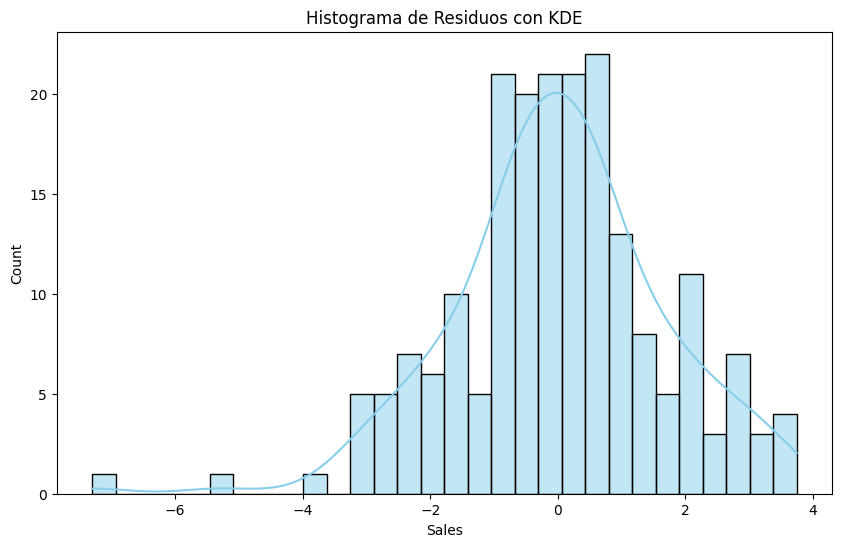

In [7]:
#Normalidad de los residuos
y_pred = model.predict(X_scaled)
residuos = y - y_pred

plt.figure(figsize=(10, 6))
sns.histplot(residuos, kde=True, bins=30, color='skyblue')
plt.title('Histograma de Residuos con KDE')


**¿Los residuos parecen distribuirse normalmente?**

Los residuos no se distribuyen completamente de forma normal. Aunque el centro está cerca de cero, la distribución muestra una asimetría negativa (sesgada a la izquierda) debido a valores atípicos entre $-4$ y $-7$.   

Los valores negativos extremos indican observaciones donde el modelo sobreestimó fuertemente las ventas. Esto implica que el supuesto de normalidad en los errores de la regresión lineal se viola ligeramente, lo cual puede distorsionar las pruebas de significancia estadística ($p$-values) e indica que el modelo actual no capta ciertos patrones no lineales o interacciones entre los medios de comunicación.

### 4.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

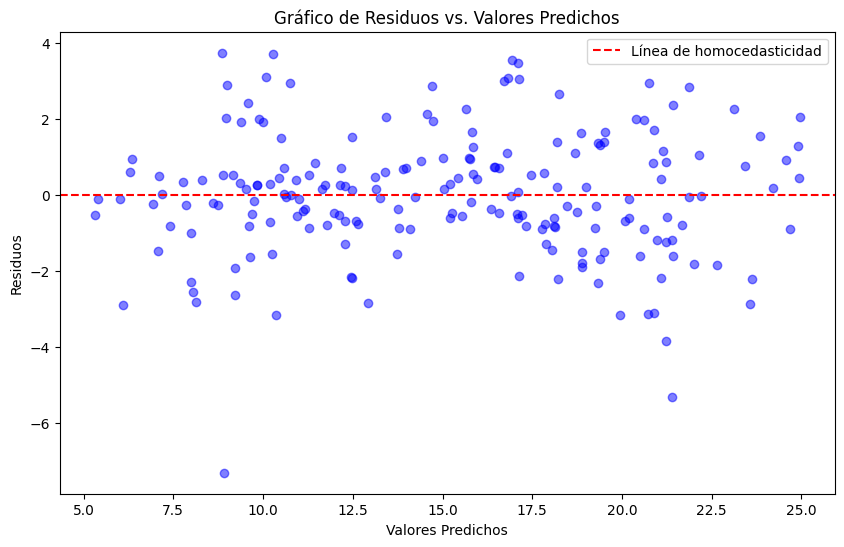

In [8]:
# Homocedasticidad

plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuos, alpha=0.5, color='blue')
plt.axhline(y=0, color='red', linestyle='--', label='Línea de homocedasticidad')
plt.xlabel('Valores Predichos')
plt.ylabel('Residuos')
plt.title('Gráfico de Residuos vs. Valores Predichos')
plt.legend()
plt.show()

**¿Observas patrones?**

Embudamiento (Heterocedasticidad): La variabilidad de los residuos crece a medida que los valores predichos aumentan (la nube de puntos se vuelve más ancha hacia la derecha).

Valores atípicos extremos: Se aprecian errores atípicos hacia abajo (residuos por debajo de $-4$ y $-7$), reflejando casos donde el modelo sobreestimó drásticamente la venta real.

El supuesto de homocedasticidad se cumple solo de forma aproximada, lo que sugiere que agregar términos no lineales (como $\text{TV}^2$) o interacciones ($\text{TV} \times \text{Radio}$) mejoraría la estabilidad de los errores.

**¿Los residuos se dispersan aleatoriamente?**

Aunque la mayoría de los puntos se distribuyen alrededor de la línea cero, no es una dispersión completamente aleatoria (homocedástica)

### 4.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

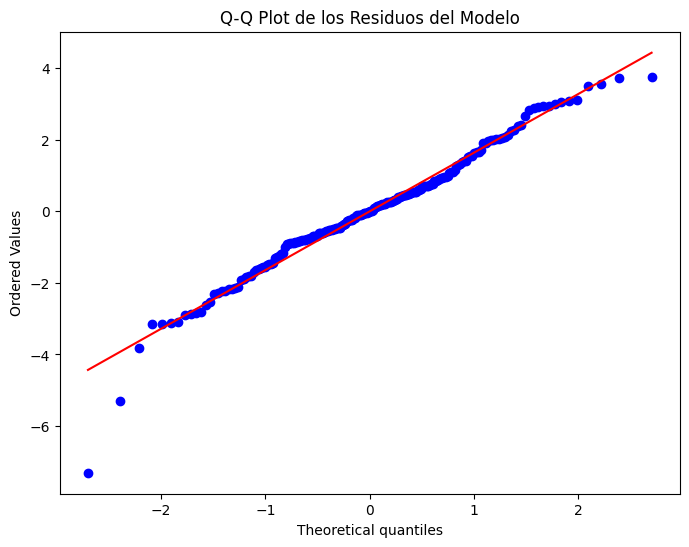

In [9]:
#Q-Q Plot

# 2. Graficar el Q-Q Plot
plt.figure(figsize=(8, 6))
stats.probplot(residuos, dist="norm", plot=plt)

# Añadir título
plt.title("Q-Q Plot de los Residuos del Modelo")

# Mostrar la gráfica
plt.show()

**a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal.**
* En el tramo central (entre $-1.5$ y $+1.5$), los residuos se ajustan estrechamente a la línea diagonal roja, lo que indica que la mayor parte de los errores siguen una distribución normal.

**b) Desviaciones sistemáticas indican asimetría o colas pesadas.**
* Los puntos caen marcadamente por debajo de la recta de referencia cerca de $-5$ y $-7.5$, lo que refleja la presencia de colores pesadas a la izquierda (asimetría negativa).

El supuesto de normalidad de los residuos se cumple de forma general en la zona media, pero se ve violado en los extremos debido a casos donde el modelo sobreestimó de forma atípica las ventas.

### 4.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [10]:
#Evaluación del Modelo

#Calcular las métricas del modelo
mse = mean_squared_error(y, y_pred)  # Error cuadrático medio
rmse = np.sqrt(mse)  # Raíz del error cuadrático medio
mae = mean_absolute_error(y, y_pred)  # Error absoluto medio
r2 = r2_score(y, y_pred)  # Coeficiente de determinación R^2

#Mostrar las métricas
print(f"Error Cuadrático Medio (MSE): {mse:.4f}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse:.4f}")
print(f"Error Absoluto Medio (MAE): {mae:.4f}")
print(f"Coeficiente de Determinación (R²): {r2:.4f}")


Error Cuadrático Medio (MSE): 2.7060
Raíz del Error Cuadrático Medio (RMSE): 1.6450
Error Absoluto Medio (MAE): 1.2364
Coeficiente de Determinación (R²): 0.9026


**Calidad del ajuste** ($R^2 = 0.9026$):

El modelo presenta un excelente poder explicativo, logrando capturar más del $90\%$ de la variabilidad en las ventas con las variables de medios publicitarios.   

**Magnitud del error** ($\text{RMSE} = 1.6450$, $\text{MAE} = 1.2364$):

En promedio, las predicciones del modelo se equivocan en apenas $1.24$ a $1.65$ unidades de ventas.   

**Efecto de valores atípicos:**

La brecha entre el RMSE ($1.645$) y el MAE ($1.236$) confirma visual y numéricamente el impacto de los pocos errores atípicos negativos identificados en el análisis de residuos (casos aislados donde las ventas reales fueron muy inferiores a lo previsto por el modelo).

### 4.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.
3. ¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

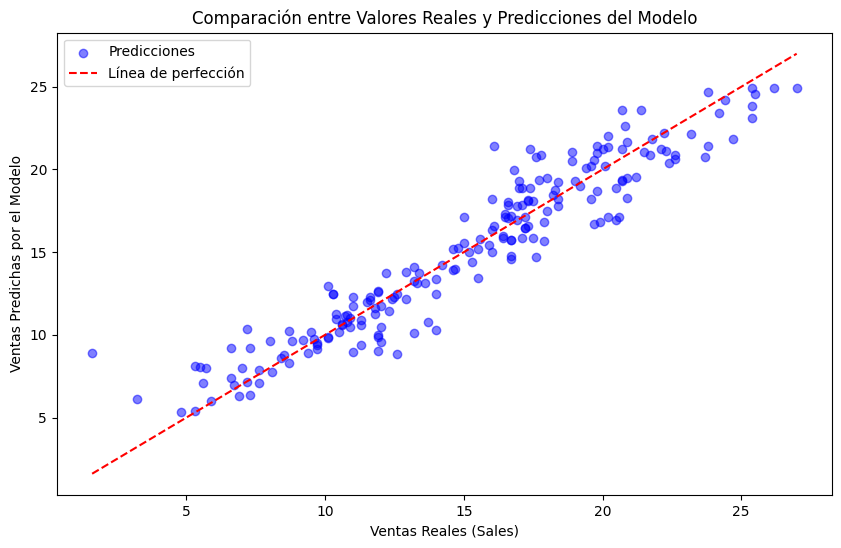


Comparación entre las predicciones y los valores reales:
   Valor Real  Predicción
0        22.1   21.220972
1        10.4   11.268248
2        12.0   10.496209
3        16.5   17.312447
4        17.9   15.644137


In [11]:
#Visualización de las Predicciones
#Graficar los valores reales frente a las predicciones
plt.figure(figsize=(10, 6))

# Graficar los valores reales vs las predicciones
plt.scatter(y, y_pred, alpha=0.5, color='blue', label='Predicciones')
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', label='Línea de perfección')


# Añadir título y etiquetas
plt.title("Comparación entre Valores Reales y Predicciones del Modelo")
plt.xlabel("Ventas Reales (Sales)")
plt.ylabel("Ventas Predichas por el Modelo")

# Añadir leyenda
plt.legend()

# Mostrar la gráfica
plt.show()

#Comparar los primeros valores reales con las predicciones
comparison = pd.DataFrame({
    'Valor Real': y.head(),
    'Predicción': y_pred[:5]  # Primeras 5 predicciones
})

print("\nComparación entre las predicciones y los valores reales:")
print(comparison)

**¿Qué observas?**

* La inmensa mayoría de los puntos azules agrupados siguen de manera clara y directa la línea roja discontinua de $45^\circ$ (la línea de perfección donde $\text{Valor Real} = \text{Predicción}$).
* Entre los valores reales de $10$ y $20$, la dispersión es muy simétrica alrededor de la línea ideal. Dando indices a dispersion homogenea.

* En la zona inferior izquierda (ventas reales bajas alrededor de $1$ a $3$), se observan dos puntos azules muy por encima de la línea roja (por ejemplo, cuando la venta real era casi $1$, el modelo predijo cerca de $9$). Esto coincide exactamente con los errores negativos que vimos en el Q-Q plot e histograma de residuos, outliers.

**¿Qué información puedes obtener de esta gráfica?**

* La alta concentración de observaciones sobre la diagonal demuestra visualmente por qué el coeficiente de determinación es tan elevado. El modelo logra capturar la variabilidad de las ventas en casi todo el rango de operación.  ($R^2 \approx 0.90$)

* Al no haber una desviación sistemática por arriba o por debajo de la recta de referencia, se concluye que el modelo no sobreestima ni subestima de manera generalizada las ventas; sus errores globales están bien centrados en cero.

* Muestra que el modelo es menos confiable cuando las ventas reales son extremadamente bajas (menores a 5). En esos escenarios, el presupuesto invertido sugeriría ventas más altas, pero el mercado no respondió, lo que alerta sobre posibles factores externos no considerados por el modelo en esos casos específicos.

### 4.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


In [12]:
#P-values
# Definición limpia desde las variables sin escalado previo de constante
X = df[['TV', 'Radio', 'Newspaper']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Agregar la constante UNA SOLA VEZ
X_scaled_with_constant = sm.add_constant(X_scaled)

# Ajustar OLS
model_sm = sm.OLS(y, X_scaled_with_constant).fit()
print(model_sm.summary())


                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        20:23:04   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         15.1305      0.117    128.771      0.0

**¿Qué variables tienen p-value menores a 0.05?**

* const: Intercepto ($15.1305$)   
* x1: TV ($\text{coef} = 4.6627$, $P>\vert{}t\vert{} = 0.000$)   
* x2: Radio ($\text{coef} = 1.5847$, $P>\vert{}t\vert{} = 0.000$)   

**¿Cuál es la conclusión sobre esas variables?**

const, TV y Radio ($p < 0.05$)

Son estadísticamente significativas para predecir las ventas con un nivel de confianza superior al $95\%$ ($\alpha = 0.05$). Existe evidencia sólida de que los presupuestos asignados a Televisión y Radio influyen directamente en la variación de las ventas. Deben conservarse obligatoriamente en el modelo.

Newspaper ($p = 0.954 > 0.05$):

NO es estadísticamente significativa en presencia de las demás variables.    Aunque de forma aislada en la correlación inicial mostró un pequeño impacto ($0.16$), cuando el modelo considera TV y Radio, la variable Newspaper no aporta ninguna información adicional útil. El presupuesto invertido en periódicos no explica los cambios en las ventas, por lo que la recomendación estratégica/técnica es eliminar Newspaper del modelo final y reasignar dicho presupuesto a Televisión o Radio.

##Parte 5:  Construcción del Modelo (sin Multicolinealidad), Evaluación

En el caso de que hayas detectado variables con multicolinealidad. Elimina aquellas que presenten esta característica y realiza los mismos pasos **que la parte 4.** Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

Durante la Parte 3 no se detectaron problemas de multicolinealidad ($\text{VIF} < 1.15$ para todas las variables). Sin embargo, al evaluar la significancia de los atributos mediante la prueba de hipótesis t en la Parte 4, se identificó que Newspaper carece de significancia estadística ($p = 0.954$).

## Parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal), Evaluación

En el caso de que hayas detectado variables sin una relación lineal. Elimina aquellas que presenten esta característica y realiza los mismos pasos **que la parte 4**.
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

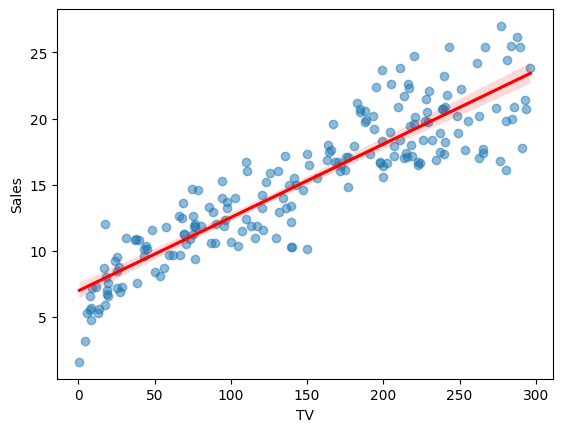

           Pearson (Lineal)  Spearman (Monótona)
TV                 0.901208             0.900996
Radio              0.349631             0.339949
Newspaper          0.157960             0.123027
Sales              1.000000             1.000000


In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

# Graficar variable por variable contra 'Sales'
sns.regplot(x=df['TV'], y=df['Sales'], scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.show()

# Comparar ambas correlaciones con la variable dependiente
pearson = df.corr(method='pearson')['Sales']
spearman = df.corr(method='spearman')['Sales']

import pandas as pd
comparacion = pd.DataFrame({'Pearson (Lineal)': pearson, 'Spearman (Monótona)': spearman})
print(comparacion)

Dada las pruebas realizadas con Pearson y Spearman, se puede determinar que Newspaper no tiene una relacion relevante por lo que se realiza la parte 4 nuevamente sin este.

In [24]:
#Entrenamiento del Modelo (Todas las Variables Independientes)
X_opt = df[['TV', 'Radio']]
y = df['Sales']


scaler = StandardScaler()
X_opt_scaled = scaler.fit_transform(X_opt)
model = LinearRegression()
model.fit(X_opt_scaled,y)

LinearRegression()

In [25]:
# Mostrar resultados limpios por variable
for var, coef in zip(X_opt.columns, model.coef_):
    print(f"Coeficiente estandarizado de {var}: {coef:.4f}")

print(f"Intercepto: {model.intercept_:.4f}")

Coeficiente estandarizado de TV: 4.6630
Coeficiente estandarizado de Radio: 1.5872
Intercepto: 15.1305


Text(0.5, 1.0, 'Histograma de Residuos con KDE')

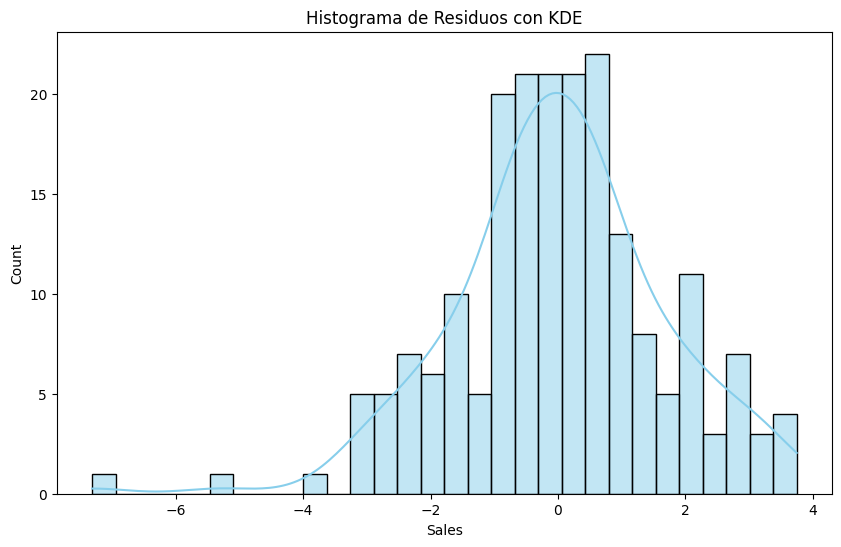

In [27]:
#Normalidad de los residuos
y_pred = model.predict(X_opt_scaled)
residuos = y - y_pred

plt.figure(figsize=(10, 6))
sns.histplot(residuos, kde=True, bins=30, color='skyblue')
plt.title('Histograma de Residuos con KDE')

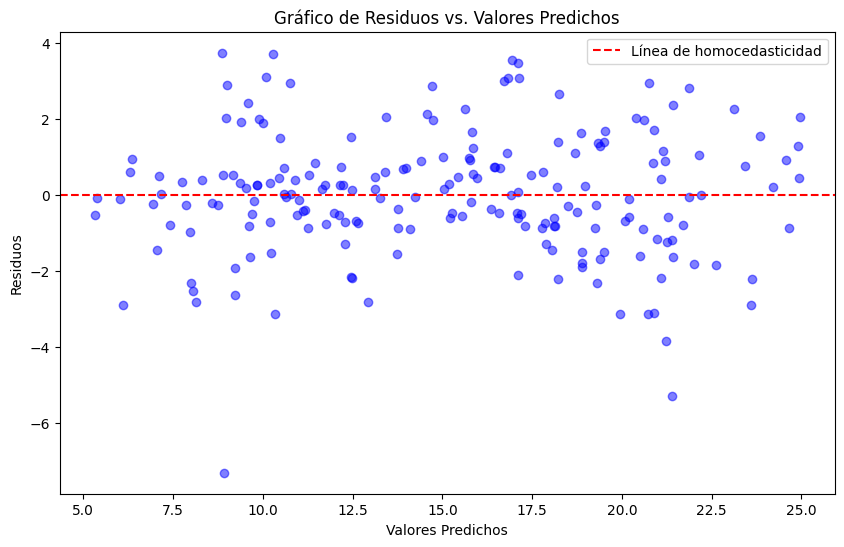

In [28]:
# Homocedasticidad

plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuos, alpha=0.5, color='blue')
plt.axhline(y=0, color='red', linestyle='--', label='Línea de homocedasticidad')
plt.xlabel('Valores Predichos')
plt.ylabel('Residuos')
plt.title('Gráfico de Residuos vs. Valores Predichos')
plt.legend()
plt.show()

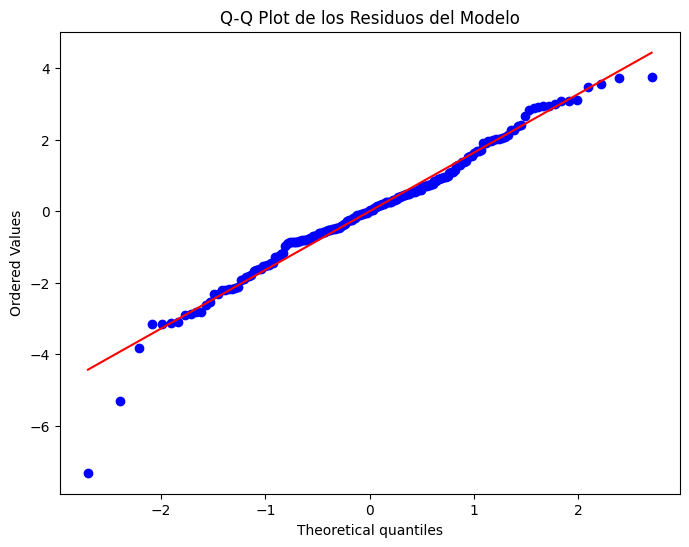

In [29]:
#Q-Q Plot

# 2. Graficar el Q-Q Plot
plt.figure(figsize=(8, 6))
stats.probplot(residuos, dist="norm", plot=plt)

# Añadir título
plt.title("Q-Q Plot de los Residuos del Modelo")

# Mostrar la gráfica
plt.show()

In [30]:
#Evaluación del Modelo

#Calcular las métricas del modelo
mse = mean_squared_error(y, y_pred)  # Error cuadrático medio
rmse = np.sqrt(mse)  # Raíz del error cuadrático medio
mae = mean_absolute_error(y, y_pred)  # Error absoluto medio
r2 = r2_score(y, y_pred)  # Coeficiente de determinación R^2

#Mostrar las métricas
print(f"Error Cuadrático Medio (MSE): {mse:.4f}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse:.4f}")
print(f"Error Absoluto Medio (MAE): {mae:.4f}")
print(f"Coeficiente de Determinación (R²): {r2:.4f}")

Error Cuadrático Medio (MSE): 2.7061
Raíz del Error Cuadrático Medio (RMSE): 1.6450
Error Absoluto Medio (MAE): 1.2368
Coeficiente de Determinación (R²): 0.9026


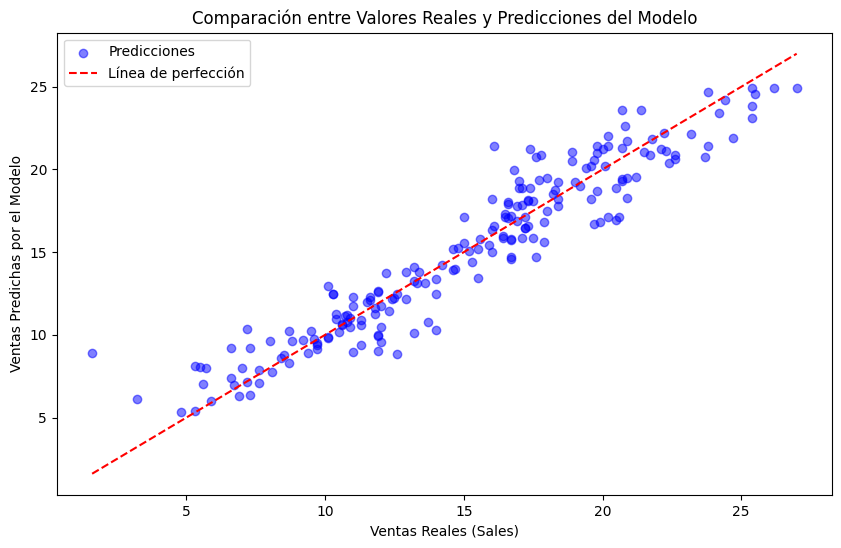


Comparación entre las predicciones y los valores reales:
   Valor Real  Predicción
0        22.1   21.210784
1        10.4   11.265819
2        12.0   10.486714
3        16.5   17.306207
4        17.9   15.632737


In [32]:
#Visualización de las Predicciones
#Graficar los valores reales frente a las predicciones
plt.figure(figsize=(10, 6))

# Graficar los valores reales vs las predicciones
plt.scatter(y, y_pred, alpha=0.5, color='blue', label='Predicciones')
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', label='Línea de perfección')


# Añadir título y etiquetas
plt.title("Comparación entre Valores Reales y Predicciones del Modelo")
plt.xlabel("Ventas Reales (Sales)")
plt.ylabel("Ventas Predichas por el Modelo")

# Añadir leyenda
plt.legend()

# Mostrar la gráfica
plt.show()

#Comparar los primeros valores reales con las predicciones
comparison = pd.DataFrame({
    'Valor Real': y.head(),
    'Predicción': y_pred[:5]  # Primeras 5 predicciones
})

print("\nComparación entre las predicciones y los valores reales:")
print(comparison)

In [33]:
#P-values

# Agregar la constante UNA SOLA VEZ
X_scaled_with_constant = sm.add_constant(X_opt_scaled)

# Ajustar OLS
model_sm = sm.OLS(y, X_scaled_with_constant).fit()
print(model_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     912.7
Date:                Wed, 28 Oct 2026   Prob (F-statistic):          2.39e-100
Time:                        20:34:57   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             772.7
Df Residuals:                     197   BIC:                             782.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         15.1305      0.117    129.098      0.0

La comparación lado a lado confirma el principio de parsimonia: al eliminar Newspaper, el modelo mantiene la misma precisión predictiva ($R^2 = 0.9026$, $\text{RMSE} = 1.6450$), reduce sus criterios de información ($\text{AIC} = 772.7$ vs $774.7$), incrementa la fuerza global del modelo ($\text{F-stat} = 912.7$ vs $605.4$) y garantiza que el $100\%$ de sus variables sean estadísticamente significativas ($p < 0.05$). Se recomienda destinar el presupuesto publicitario únicamente a Televisión y Radio.

##7. Conclusiones.

¿Cuál de los tres modelos construidos fue el mejor?
¿Cuál fue el atributo que mas influencia tiene en las ventas?

El modelo optimizado (sin Newspaper) es el mejor por ser más parsimonioso, ofreciendo exactamente la misma capacidad explicativa ($R^2 = 90.26\%$) con métricas de información superiores ($\text{AIC} = 772.7$, $\text{F-stat} = 912.7$). Asimismo, TV se consolida como el canal publicitario con mayor impacto directo sobre las ventas ($r = 0.901$, $\beta = 4.663$), seguido por Radio, mientras que la inversión en periódicos demostró no ser estadísticamente significativa.  